In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Loads the csv file
df = pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [23]:
#Describes the dataset
print("Shape:", df.shape)
print(df.dtypes)
df.describe()

Shape: (344, 7)
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [24]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["sex"].value_counts())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Duplicate rows: 0
sex
MALE      168
FEMALE    165
Name: count, dtype: int64


In [25]:
df_clean = df.copy()

# Drop rows that have no measurements at all
df_clean = df_clean.dropna(subset=["body_mass_g"])

# Make the text consistent (Male / Female)
df_clean["sex"] = df_clean["sex"].str.title()

# Fill the missing sex values with "Unknown"
df_clean["sex"] = df_clean["sex"].fillna("Unknown")

print(df_clean.isnull().sum())
print(df_clean.shape)

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64
(342, 7)


In [26]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(col, "outliers:", n)

bill_length_mm outliers: 0
bill_depth_mm outliers: 0
flipper_length_mm outliers: 0
body_mass_g outliers: 0


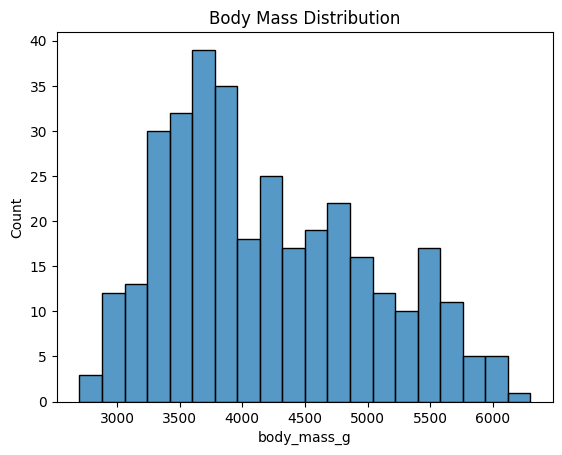

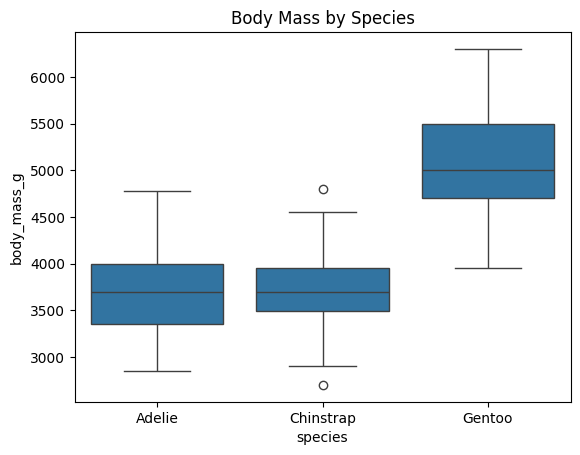

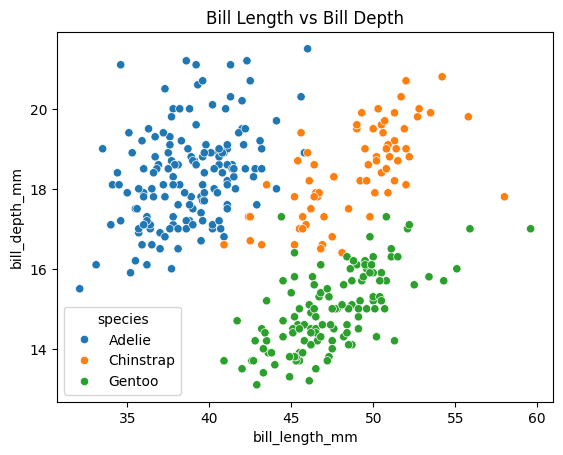

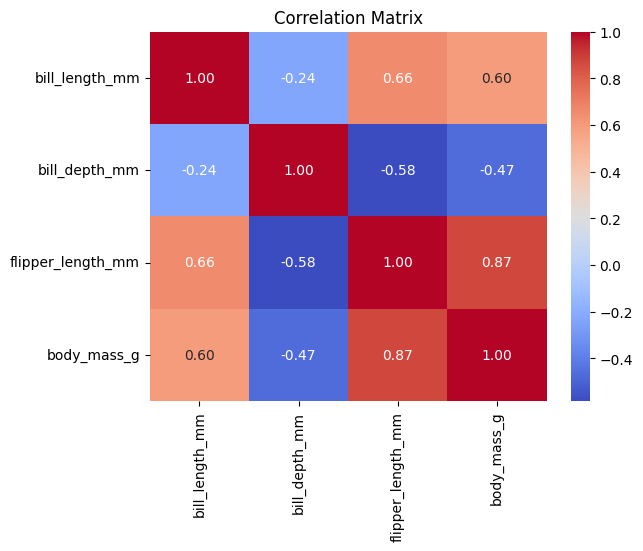

In [27]:
#creates the chrats
sns.histplot(df_clean["body_mass_g"], bins=20)
plt.title("Body Mass Distribution")
plt.show()

sns.boxplot(x="species", y="body_mass_g", data=df_clean)
plt.title("Body Mass by Species")
plt.show()

sns.scatterplot(x="bill_length_mm", y="bill_depth_mm", hue="species", data=df_clean)
plt.title("Bill Length vs Bill Depth")
plt.show()

sns.heatmap(df_clean[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

## Key Observations
1. Gentoo penguins are the heaviest, at around 5,000 g on average.
2. Flipper length and body mass are strongly linked (about 0.87).
3. Each species forms its own cluster in the bill length vs bill depth plot.